<a href="https://colab.research.google.com/github/pratham-239/ML-Project/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHASE 1

In [ ]:
# from google.colab import files
# uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("All Electronics.csv")

print(df.shape)
print(df.columns)
df.head()

(9600, 9)
Index(['name', 'main_category', 'sub_category', 'image', 'link', 'ratings',
       'no_of_ratings', 'discount_price', 'actual_price'],
      dtype='object')


,name,main_category,sub_category,image,link,ratings,no_of_ratings,discount_price,actual_price
0,"Redmi 10 Power (Power Black, 8GB RAM, 128GB St...","tv, audio & cameras",All Electronics,https://m.media-amazon.com/images/I/81eM15lVcJ...,https://www.amazon.in/Redmi-Power-Black-128GB-...,4.0,965,"₹10,999","₹18,999"
1,"OnePlus Nord CE 2 Lite 5G (Blue Tide, 6GB RAM,...","tv, audio & cameras",All Electronics,https://m.media-amazon.com/images/I/71AvQd3Vzq...,https://www.amazon.in/OnePlus-Nord-Lite-128GB-...,4.3,"113,956","₹18,999","₹19,999"
2,OnePlus Bullets Z2 Bluetooth Wireless in Ear E...,"tv, audio & cameras",All Electronics,https://m.media-amazon.com/images/I/51UhwaQXCp...,https://www.amazon.in/Oneplus-Bluetooth-Wirele...,4.2,"90,304","₹1,999","₹2,299"
3,"Samsung Galaxy M33 5G (Mystique Green, 6GB, 12...","tv, audio & cameras",All Electronics,https://m.media-amazon.com/images/I/81I3w4J6yj...,https://www.amazon.in/Samsung-Mystique-Storage...,4.1,"24,863","₹15,999","₹24,999"
4,"OnePlus Nord CE 2 Lite 5G (Black Dusk, 6GB RAM...","tv, audio & cameras",All Electronics,https://m.media-amazon.com/images/I/71V--WZVUI...,https://www.amazon.in/OnePlus-Nord-Black-128GB...,4.3,"113,956","₹18,999","₹19,999"


In [ ]:
df.info()
df.isnull().sum()
df["discount_price"].head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9600 entries, 0 to 9599
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   name            9600 non-null   object
 1   main_category   9600 non-null   object
 2   sub_category    9600 non-null   object
 3   image           9600 non-null   object
 4   link            9600 non-null   object
 5   ratings         9505 non-null   object
 6   no_of_ratings   9505 non-null   object
 7   discount_price  9116 non-null   object
 8   actual_price    9530 non-null   object
dtypes: object(9)
memory usage: 675.1+ KB


,discount_price
0,"₹10,999"
1,"₹18,999"
2,"₹1,999"
3,"₹15,999"
4,"₹18,999"
5,"₹10,999"
6,"₹1,299"
7,"₹1,589"
8,"₹1,799"
9,"₹15,999"


In [ ]:
df["discount_price"] = df["discount_price"].str.replace("₹", "")
df["discount_price"] = df["discount_price"].str.replace(",", "")
df["discount_price"] = pd.to_numeric(df["discount_price"], errors="coerce")
print(df["discount_price"].head(10))
df["discount_price"].mean()

0    10999.0
1    18999.0
2     1999.0
3    15999.0
4    18999.0
5    10999.0
6     1299.0
7     1589.0
8     1799.0
9    15999.0
Name: discount_price, dtype: float64


np.float64(2976.2755923650725)

In [ ]:
df["actual_price"] = df["actual_price"].str.replace("₹", "")
df["actual_price"] = df["actual_price"].str.replace(",", "")
df["actual_price"] = pd.to_numeric(df["actual_price"], errors="coerce")

df["no_of_ratings"] = df["no_of_ratings"].str.replace(",", "")
df["no_of_ratings"] = pd.to_numeric(df["no_of_ratings"], errors="coerce")

df["ratings"] = pd.to_numeric(df["ratings"], errors="coerce")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9600 entries, 0 to 9599
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   name            9600 non-null   object 
 1   main_category   9600 non-null   object 
 2   sub_category    9600 non-null   object 
 3   image           9600 non-null   object 
 4   link            9600 non-null   object 
 5   ratings         9481 non-null   float64
 6   no_of_ratings   9481 non-null   float64
 7   discount_price  9116 non-null   float64
 8   actual_price    9530 non-null   float64
dtypes: float64(4), object(5)
memory usage: 675.1+ KB


In [ ]:
print("Rows before:", len(df))

df = df.dropna(subset=["discount_price"])

print("Rows after:", len(df))

Rows before: 9600
Rows after: 9116


In [ ]:
middle_rating = df["ratings"].median()
print("Median rating:", middle_rating)

df["ratings"] = df["ratings"].fillna(middle_rating)
df["no_of_ratings"] = df["no_of_ratings"].fillna(0)

Median rating: 4.1


In [ ]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("Rows now:", len(df))

Duplicates: 0
Rows now: 9116


In [ ]:
df = df.drop(columns=["image", "link"], errors="ignore")

In [ ]:
print(df.shape)
print(df.isnull().sum())
df.head()

(9116, 7)
name              0
main_category     0
sub_category      0
ratings           0
no_of_ratings     0
discount_price    0
actual_price      0
dtype: int64


,name,main_category,sub_category,ratings,no_of_ratings,discount_price,actual_price
0,"Redmi 10 Power (Power Black, 8GB RAM, 128GB St...","tv, audio & cameras",All Electronics,4.0,965.0,10999.0,18999.0
1,"OnePlus Nord CE 2 Lite 5G (Blue Tide, 6GB RAM,...","tv, audio & cameras",All Electronics,4.3,113956.0,18999.0,19999.0
2,OnePlus Bullets Z2 Bluetooth Wireless in Ear E...,"tv, audio & cameras",All Electronics,4.2,90304.0,1999.0,2299.0
3,"Samsung Galaxy M33 5G (Mystique Green, 6GB, 12...","tv, audio & cameras",All Electronics,4.1,24863.0,15999.0,24999.0
4,"OnePlus Nord CE 2 Lite 5G (Black Dusk, 6GB RAM...","tv, audio & cameras",All Electronics,4.3,113956.0,18999.0,19999.0


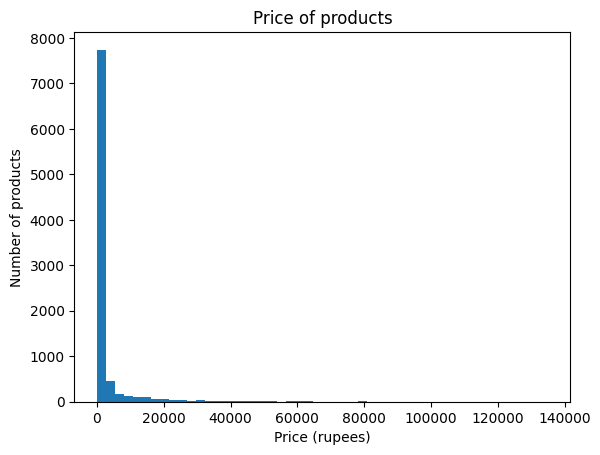

In [ ]:
import matplotlib.pyplot as plt
plt.hist(df["discount_price"], bins=50)
plt.title("Price of products")
plt.xlabel("Price (rupees)")
plt.ylabel("Number of products")
plt.show()

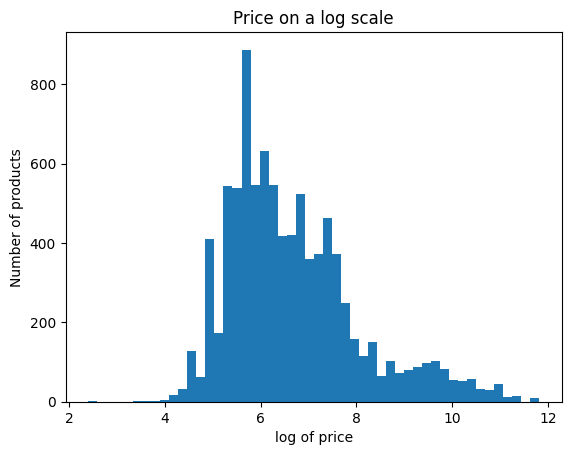

In [ ]:
import numpy as np
plt.hist(np.log1p(df["discount_price"]), bins=50)
plt.title("Price on a log scale")
plt.xlabel("log of price")
plt.ylabel("Number of products")
plt.show()

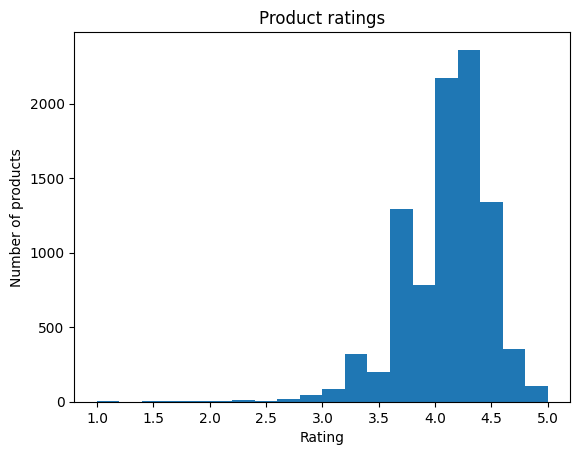

In [ ]:
plt.hist(df["ratings"], bins=20)
plt.title("Product ratings")
plt.xlabel("Rating")
plt.ylabel("Number of products")
plt.show()

In [ ]:
df["main_category"].value_counts()
df["sub_category"].value_counts()

,count
sub_category,
All Electronics,9116


In [ ]:
df["brand"] = df["name"].str.split().str[0]
df["brand"] = df["brand"].str.title()
df[["name", "brand"]].head(10)
df["brand"].value_counts().head(10)

,count
brand,
Thegiftkart,273
Boat,244
Amazon,231
Spigen,203
Zebronics,193
Samsung,142
Portronics,128
Hp,128
Amazonbasics,119


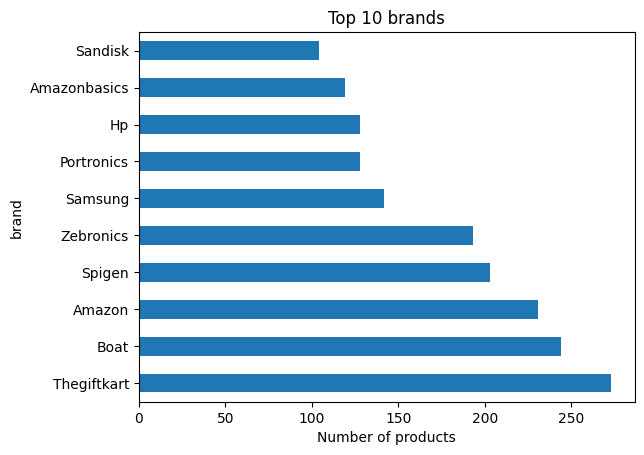

In [ ]:
top_brands = df["brand"].value_counts().head(10)

top_brands.plot(kind="barh")
plt.title("Top 10 brands")
plt.xlabel("Number of products")
plt.show()

In [ ]:
brand_price = df.groupby("brand")["discount_price"].median()
brand_price.sort_values(ascending=False).head(10)

,discount_price
brand,
Havells-Lloyd,60999.0
Apple,53999.0
Insta360,43990.0
Hisense,40999.0
Asus,39995.0
Vu,38999.0
Honor,29994.5
Dyson,27900.0
Iqoo,23999.0


In [ ]:
df["discount_price"].describe()
print(df["discount_price"].quantile([0.01, 0.50, 0.99]))

0.01       95.30
0.50      580.50
0.99    46997.65
Name: discount_price, dtype: float64


In [ ]:
df.nlargest(10, "discount_price")[["name", "discount_price"]]
df.nsmallest(10, "discount_price")[["name", "discount_price"]]

,name,discount_price
6851,Camlin Kokuyo Fine Point Sketch Pen - 12 Shade...,10.0
7852,Pidilite Fevicryl Fabric Glue (80g),29.0
8894,"Faber Castell Graded Drawing Pencil, Pack of 6...",34.0
2317,Apsara Non Dust Erasers - Pack of 20,36.0
7146,Faber-Castell Kinder Scissors(Assorted),43.8
4159,Apsara Matt Magic Pencil 2.0 [Pack of 10],45.0
5626,HIK's® Round Earphone case Earphone Pouch | Ea...,49.0
6466,Apsara Platinum Extra Dark Pencils - Pack of 10,51.0
3633,Apsara Absolute Extra Dark Pencils - Pack of 10,54.0
3531,Onsitego 1 Year Extended Warranty for Small Ho...,55.0


In [ ]:
# df.to_csv("cleaned_products.csv", index=False)

# from google.colab import files
# files.download("cleaned_products.csv")

PHASE 2

In [ ]:
df["is_renewed"] = df["name"].str.contains("Renewed", case=False)
df["is_renewed"] = df["is_renewed"].astype(int)
df["is_renewed"].value_counts()

,count
is_renewed,
0,9040
1,76


In [ ]:
df["name_length"] = df["name"].str.len()
df[["name", "name_length"]].head()

,name,name_length
0,"Redmi 10 Power (Power Black, 8GB RAM, 128GB St...",52
1,"OnePlus Nord CE 2 Lite 5G (Blue Tide, 6GB RAM,...",61
2,OnePlus Bullets Z2 Bluetooth Wireless in Ear E...,125
3,"Samsung Galaxy M33 5G (Mystique Green, 6GB, 12...",125
4,"OnePlus Nord CE 2 Lite 5G (Black Dusk, 6GB RAM...",62


In [ ]:
df["has_gb"] = df["name"].str.contains("GB", case=False).astype(int)
df["has_gb"].value_counts()

,count
has_gb,
0,8270
1,846


In [ ]:
df.groupby("is_renewed")["discount_price"].median()
df.groupby("has_gb")["discount_price"].median()

,discount_price
has_gb,
0,499.0
1,7999.0


In [ ]:
import re

df["ram_gb"] = df["name"].str.extract(r"(\d+)\s*GB\s*RAM", flags=re.IGNORECASE)[0]
df["storage_gb"] = df["name"].str.extract(r"(\d+)\s*GB\s*(?:Storage|ROM|SSD)", flags=re.IGNORECASE)[0]

In [ ]:
df["ram_gb"] = pd.to_numeric(df["ram_gb"], errors="coerce").fillna(0)
df["storage_gb"] = pd.to_numeric(df["storage_gb"], errors="coerce").fillna(0)

In [ ]:
df[df["ram_gb"] > 0][["name", "ram_gb", "storage_gb"]].head(10)
print("Products with RAM found:", (df["ram_gb"] > 0).sum())
print("Products with storage found:", (df["storage_gb"] > 0).sum())

Products with RAM found: 307
Products with storage found: 353


In [ ]:
df.groupby("ram_gb")["discount_price"].median().head(10)

,discount_price
ram_gb,
0.0,548.0
2.0,6299.0
3.0,9490.0
4.0,11794.0
6.0,15499.0
8.0,25694.5
12.0,21999.0
16.0,23240.5


In [ ]:
short_names = df["name"].str.lower().str.split("upto|up to", regex=True).str[0]

ram_a     = short_names.str.extract(r"(\d+)\s*gb\s*ram")[0]
storage_a = short_names.str.extract(r"(\d+)\s*gb\s*(?:storage|rom|ssd)")[0]
pair      = short_names.str.extract(r"(\d+)\s*gb\s*,\s*(\d+)\s*gb")

df["ram_gb"]     = ram_a.fillna(pair[0])
df["storage_gb"] = storage_a.fillna(pair[1])

df["ram_gb"]     = pd.to_numeric(df["ram_gb"], errors="coerce").fillna(0)
df["storage_gb"] = pd.to_numeric(df["storage_gb"], errors="coerce").fillna(0)

In [ ]:
print("Products with RAM found:", (df["ram_gb"] > 0).sum())
print("Products with storage found:", (df["storage_gb"] > 0).sum())

Products with RAM found: 343
Products with storage found: 372


In [ ]:
top_brands = df["brand"].value_counts().head(30).index

df["brand_group"] = df["brand"].where(df["brand"].isin(top_brands), "Other")

df["brand_group"].value_counts().head(10)

,count
brand_group,
Other,5910
Thegiftkart,273
Boat,244
Amazon,231
Spigen,203
Zebronics,193
Samsung,142
Hp,128
Portronics,128


In [ ]:
brand_cols = pd.get_dummies(df["brand_group"], prefix="brand", dtype=int)

df = pd.concat([df, brand_cols], axis=1)

print(df.shape)
df.head()

(9116, 45)


,name,main_category,sub_category,ratings,no_of_ratings,discount_price,actual_price,brand,is_renewed,name_length,...,brand_Realme,brand_Redmi,brand_Robustrion,brand_Samsung,brand_Sandisk,brand_Sounce,brand_Spigen,brand_Thegiftkart,brand_Tp-Link,brand_Zebronics
0,"Redmi 10 Power (Power Black, 8GB RAM, 128GB St...","tv, audio & cameras",All Electronics,4.0,965.0,10999.0,18999.0,Redmi,0,52,...,0,1,0,0,0,0,0,0,0,0
1,"OnePlus Nord CE 2 Lite 5G (Blue Tide, 6GB RAM,...","tv, audio & cameras",All Electronics,4.3,113956.0,18999.0,19999.0,Oneplus,0,61,...,0,0,0,0,0,0,0,0,0,0
2,OnePlus Bullets Z2 Bluetooth Wireless in Ear E...,"tv, audio & cameras",All Electronics,4.2,90304.0,1999.0,2299.0,Oneplus,0,125,...,0,0,0,0,0,0,0,0,0,0
3,"Samsung Galaxy M33 5G (Mystique Green, 6GB, 12...","tv, audio & cameras",All Electronics,4.1,24863.0,15999.0,24999.0,Samsung,0,125,...,0,0,0,1,0,0,0,0,0,0
4,"OnePlus Nord CE 2 Lite 5G (Black Dusk, 6GB RAM...","tv, audio & cameras",All Electronics,4.3,113956.0,18999.0,19999.0,Oneplus,0,62,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# df.to_csv("features_products.csv", index=False)

# from google.colab import files
# files.download("features_products.csv")

PHASE 3

In [ ]:
y = np.log1p(df["discount_price"])
y.head()

,discount_price
0,9.305651
1,9.852194
2,7.600902
3,9.680344
4,9.852194


In [ ]:
basic_features = ["ratings", "no_of_ratings", "is_renewed",
                  "name_length", "has_gb", "ram_gb", "storage_gb"]
brand_features = [c for c in df.columns if c.startswith("brand_") and c != "brand_group"]
print(len(brand_features), "brand columns")

31 brand columns


In [ ]:
all_features = basic_features + brand_features
X = df[all_features]

print(X.shape)
print(X.isnull().sum().sum())

(9116, 38)
0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training products:", len(X_train))
print("Test products:", len(X_test))

Training products: 7292
Test products: 1824


In [ ]:
from sklearn.metrics import mean_absolute_error

def show_score(name, guesses_log):
    guesses = np.expm1(guesses_log)       # log price -> rupees
    real = np.expm1(y_test)               # log price -> rupees
    mae = mean_absolute_error(real, guesses)
    print(name, "-> average mistake: Rs", round(mae))

In [ ]:
median_log_price = y_train.median()

lazy_guesses = np.full(len(y_test), median_log_price)

show_score("Lazy baseline", lazy_guesses)

Lazy baseline -> average mistake: Rs 2892


In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
forest_guesses = model.predict(X_test)

show_score("Random Forest", forest_guesses)

Random Forest -> average mistake: Rs 1559


In [ ]:
check = pd.DataFrame({
    "name": df.loc[X_test.index, "name"],
    "real_price": np.expm1(y_test).round(),
    "guess": np.expm1(forest_guesses).round()
})
check.head(15)

,name,real_price,guess
1705,SanDisk Ultra Dual 32 GB USB 3.0 OTG Pen Drive...,429.0,600.0
8347,"Palazzo Foldable Wooden Laptop Bed Tray Table,...",399.0,407.0
8906,(Renewed) DELL Latitude 5490 Core i5 7th Gen L...,22482.0,20271.0
8525,ZYBUX iPhone 14 / iPhone 14 Plus Metal Rings B...,269.0,496.0
7102,MAXELL Lr41 Ag3 Lr736 392 392a 192 Sr41 BUTTON...,153.0,595.0
7500,Robustrion Smart Trifold Hard Back Flip Stand ...,599.0,327.0
1907,Amazon Basics Bluetooth 5.0 Truly Wireless in ...,899.0,719.0
5626,HIK's® Round Earphone case Earphone Pouch | Ea...,49.0,2051.0
4539,PTron Newly Launched Musicbot Lite 5W Mini Blu...,495.0,545.0
4821,INVICTO TG113 Portable Bluetooth Speaker with ...,299.0,467.0


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

word_tool = CountVectorizer(binary=True, max_features=300, stop_words="english")

word_table = word_tool.fit_transform(df["name"])

word_names = ["word_" + w for w in word_tool.get_feature_names_out()]

words_df = pd.DataFrame(word_table.toarray(), columns=word_names, index=df.index)

print(words_df.shape)
words_df.iloc[:5, :10]

(9116, 300)


,word_10,word_100,word_1080p,word_11,word_12,word_128gb,word_13,word_14,word_15,word_20
0,1,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0
2,1,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0


In [ ]:
X2 = pd.concat([X, words_df], axis=1)

print("Before:", X.shape)
print("After:", X2.shape)

Before: (9116, 38)
After: (9116, 338)


In [ ]:
X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.2, random_state=42
)

model2 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model2.fit(X2_train, y_train)

guesses2 = np.expm1(model2.predict(X2_test))
real_prices = np.expm1(y_test)

new_mistake = (real_prices - guesses2).abs().mean()
print("Random Forest with words is wrong by about Rs", round(new_mistake))

Random Forest with words is wrong by about Rs 1068


In [ ]:
importance = pd.Series(model2.feature_importances_, index=X2.columns)
importance.sort_values(ascending=False).head(15)

,0
storage_gb,0.233202
word_cm,0.055273
no_of_ratings,0.050375
ratings,0.042219
has_gb,0.033766
name_length,0.032476
word_bluetooth,0.032417
word_cover,0.022905
word_wireless,0.021424
word_apple,0.018491


In [ ]:
def percent_mistake(real, guess):
    each = (real - guess).abs() / real * 100
    return each.median()

real_prices = np.expm1(y_test)

lazy_rupees   = np.expm1(lazy_guesses)
forest_rupees = np.expm1(forest_guesses)
words_rupees  = np.expm1(model2.predict(X2_test))

print("Lazy assistant:        ", round(percent_mistake(real_prices, lazy_rupees)), "% off")
print("Forest (first model):  ", round(percent_mistake(real_prices, forest_rupees)), "% off")
print("Forest (with words):   ", round(percent_mistake(real_prices, words_rupees)), "% off")

Lazy assistant:         71 % off
Forest (first model):   39 % off
Forest (with words):    23 % off


In [ ]:
from sklearn.metrics import r2_score

print("R2 first model:  ", round(r2_score(y_test, model.predict(X_test)), 2))
print("R2 with words:   ", round(r2_score(y_test, model2.predict(X2_test)), 2))

R2 first model:   0.51
R2 with words:    0.78


In [ ]:
check = pd.DataFrame({
    "name": df.loc[X2_test.index, "name"],
    "real_price": real_prices.round(),
    "guess": words_rupees.round()
})
check["percent_off"] = ((check["real_price"] - check["guess"]).abs() / check["real_price"] * 100).round()

check.sort_values("percent_off", ascending=False).head(10)

,name,real_price,guess,percent_off
5549,Cello Signature Creme Ivory Roller Pen | Premi...,219.0,4364.0,1893.0
8402,Western Digital WD Green 240 GB 6.35 cm (2.5 i...,1485.0,23194.0,1462.0
484,"Lapster Caddy for ssd and HDD, Optical Bay 2nd...",150.0,1434.0,856.0
7852,Pidilite Fevicryl Fabric Glue (80g),29.0,234.0,707.0
8189,PIXELARTZ Laptop Skin Day Dreaming Abstract Gr...,190.0,1468.0,673.0
9032,Pidilite Fevicol 200 Gram Craft Glue Ultimate ...,98.0,722.0,637.0
8894,"Faber Castell Graded Drawing Pencil, Pack of 6...",34.0,247.0,626.0
6528,UT Bluetooth FM USB AUX Card MP3 Stereo Audio ...,175.0,1214.0,594.0
263,Sounce Shutter Remote Control with Bluetooth W...,169.0,1162.0,588.0
1247,"ZEBRONICS SD13 128GB SSD,Ultra Low Power Consu...",848.0,5760.0,579.0


In [ ]:
from sklearn.metrics import r2_score

real_prices = np.expm1(y_test)

def percent_mistake(real, guess):
    each = (real - guess).abs() / real * 100
    return each.median()

def score_model(name, trained_model):
    guesses_log = trained_model.predict(X2_test)
    guesses = np.expm1(guesses_log)
    pct = round(percent_mistake(real_prices, guesses))
    mae = round((real_prices - guesses).abs().mean())
    r2 = round(r2_score(y_test, guesses_log), 2)
    print(name, "-> typical error:", pct, "% | average mistake: Rs", mae, "| R2:", r2)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

linear = LinearRegression()
linear.fit(X2_train, y_train)

tree = DecisionTreeRegressor(max_depth=15, random_state=42)
tree.fit(X2_train, y_train)

DecisionTreeRegressor(max_depth=15, random_state=42)

In [ ]:
score_model("Linear Regression", linear)
score_model("Decision Tree    ", tree)
score_model("Random Forest    ", model2)

Linear Regression -> typical error: 44 % | average mistake: Rs 1990 | R2: 0.64
Decision Tree     -> typical error: 38 % | average mistake: Rs 1280 | R2: 0.6
Random Forest     -> typical error: 23 % | average mistake: Rs 1068 | R2: 0.78


In [ ]:
import joblib

joblib.dump(model2, "price_model.joblib")
joblib.dump(word_tool, "word_tool.joblib")
joblib.dump(list(top_brands), "top_brands.joblib")
joblib.dump(list(X2.columns), "feature_columns.joblib")

print("Saved 4 files")

Saved 4 files


In [ ]:
# from google.colab import files

# files.download("price_model.joblib")
# files.download("word_tool.joblib")
# files.download("top_brands.joblib")
# files.download("feature_columns.joblib")

In [ ]:
check_model = joblib.load("price_model.joblib")
score_model("Loaded model", check_model)

Loaded model -> typical error: 23 % | average mistake: Rs 1068 | R2: 0.78


PHASE 4

In [ ]:
import joblib, re
import numpy as np
import pandas as pd

model = joblib.load("price_model.joblib")
word_tool = joblib.load("word_tool.joblib")
top_brands = joblib.load("top_brands.joblib")
feature_columns = joblib.load("feature_columns.joblib")

print("Clues the model expects:", len(feature_columns))

Clues the model expects: 338


In [ ]:
row = {col: 0 for col in feature_columns}
print(list(row.items())[:5])

[('ratings', 0), ('no_of_ratings', 0), ('is_renewed', 0), ('name_length', 0), ('has_gb', 0)]


In [ ]:
name = "Samsung Galaxy M33 5G (Mystique Green, 6GB, 128GB Storage)"
rating = 4.1
num_ratings = 24000

row["ratings"] = rating
row["no_of_ratings"] = num_ratings
row["name_length"] = len(name)
row["is_renewed"] = 1 if "renewed" in name.lower() else 0
row["has_gb"] = 1 if "gb" in name.lower() else 0

In [ ]:
short = re.split("upto|up to", name.lower())[0]

ram = re.search(r"(\d+)\s*gb\s*ram", short)
storage = re.search(r"(\d+)\s*gb\s*(?:storage|rom|ssd)", short)
pair = re.search(r"(\d+)\s*gb\s*,\s*(\d+)\s*gb", short)

row["ram_gb"] = int(ram.group(1)) if ram else (int(pair.group(1)) if pair else 0)
row["storage_gb"] = int(storage.group(1)) if storage else (int(pair.group(2)) if pair else 0)

In [ ]:
brand = name.split()[0].title()
group = brand if brand in top_brands else "Other"

if "brand_" + group in row:
    row["brand_" + group] = 1

In [ ]:
word_values = word_tool.transform([name]).toarray()[0]
word_names = word_tool.get_feature_names_out()

for w, v in zip(word_names, word_values):
    row["word_" + w] = v

In [ ]:
X_new = pd.DataFrame([row])[feature_columns]

guess_log = model.predict(X_new)[0]
print("Predicted price: Rs", round(np.expm1(guess_log)))

Predicted price: Rs 18030


In [ ]:
def predict_price(name, rating=4.0, num_ratings=100):
    row = {col: 0 for col in feature_columns}

    row["ratings"] = rating
    row["no_of_ratings"] = num_ratings
    row["name_length"] = len(name)
    row["is_renewed"] = 1 if "renewed" in name.lower() else 0
    row["has_gb"] = 1 if "gb" in name.lower() else 0

    short = re.split("upto|up to", name.lower())[0]
    ram = re.search(r"(\d+)\s*gb\s*ram", short)
    storage = re.search(r"(\d+)\s*gb\s*(?:storage|rom|ssd)", short)
    pair = re.search(r"(\d+)\s*gb\s*,\s*(\d+)\s*gb", short)
    row["ram_gb"] = int(ram.group(1)) if ram else (int(pair.group(1)) if pair else 0)
    row["storage_gb"] = int(storage.group(1)) if storage else (int(pair.group(2)) if pair else 0)

    brand = name.split()[0].title()
    group = brand if brand in top_brands else "Other"
    if "brand_" + group in row:
        row["brand_" + group] = 1

    word_values = word_tool.transform([name]).toarray()[0]
    for w, v in zip(word_tool.get_feature_names_out(), word_values):
        row["word_" + w] = v

    X_new = pd.DataFrame([row])[feature_columns]
    return round(np.expm1(model.predict(X_new)[0]))

In [ ]:
print(predict_price("Samsung Galaxy M33 5G (Mystique Green, 6GB, 128GB Storage)", 4.1, 24000))
print(predict_price("Boat Bassheads 100 Wired Earphones", 4.2, 300000))
print(predict_price("Cello Gel Pen Pack of 10", 4.3, 5000))
print(predict_price("HP 15s Laptop 16GB RAM 512GB SSD", 4.2, 3000))

18030
672
74
10553


In [ ]:
sample = df.sample(5, random_state=7)

for _, r in sample.iterrows():
    guess = predict_price(r["name"], r["ratings"], r["no_of_ratings"])
    print(r["name"][:50], "| real:", round(r["discount_price"]), "| guess:", guess)

Noise Buds VS204 in-Ear Truly Wireless Earbuds wit | real: 1499 | guess: 1522
House of Quirk Electronic Bag Travel Cable Accesso | real: 599 | guess: 469
Duracell Specialty 1616 Lithium Coin Battery 3V, P | real: 203 | guess: 210
Wayona Nylon Braided (2 Pack) USB Syncing and Char | real: 599 | guess: 507
Robustrion Pack of 2 Tempered Glass Screen Protect | real: 549 | guess: 441
